In [1]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

# Load the cleaned dataset
df = pd.read_csv(
    "../Dataset/Wednesday_Cleaned.csv.gz",
    compression="gzip",
    parse_dates=["Timestamp"]
)

# Recreate the Traffic Type column
df["Traffic Type"] = np.where(
    df["Label"] == "BENIGN",
    "BENIGN",
    "ATTACK"
)

# Set visualization theme
sns.set_theme(style="whitegrid")

# Set default figure size
plt.rcParams["figure.figsize"] = (10, 6)

# Create output folders
os.makedirs("../Visualizations/Static", exist_ok=True)
os.makedirs("../Visualizations/Interactive", exist_ok=True)

print("Visualization environment is ready!")

print("\nDataset Shape:", df.shape)

print("\nOutput folders created:")
print("../Visualizations/Static/")
print("../Visualizations/Interactive/")

Visualization environment is ready!

Dataset Shape: (692686, 86)

Output folders created:
../Visualizations/Static/
../Visualizations/Interactive/


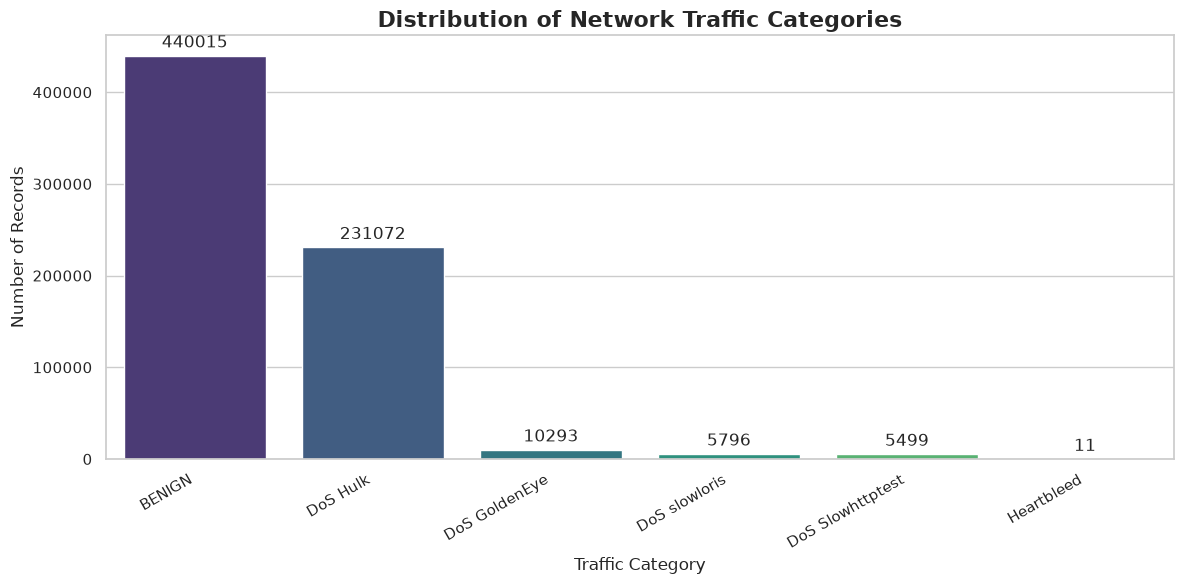

In [3]:
# Count records for each traffic label
label_counts = df["Label"].value_counts()

# Create the bar chart
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=label_counts.index,
    y=label_counts.values,
    hue=label_counts.index,
    palette="viridis",
    legend=False
)

# Display record counts above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

# Add title and axis labels
plt.title(
    "Distribution of Network Traffic Categories",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Traffic Category", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

# Save the visualization
plt.savefig(
    "../Visualizations/Static/01_Traffic_Category_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

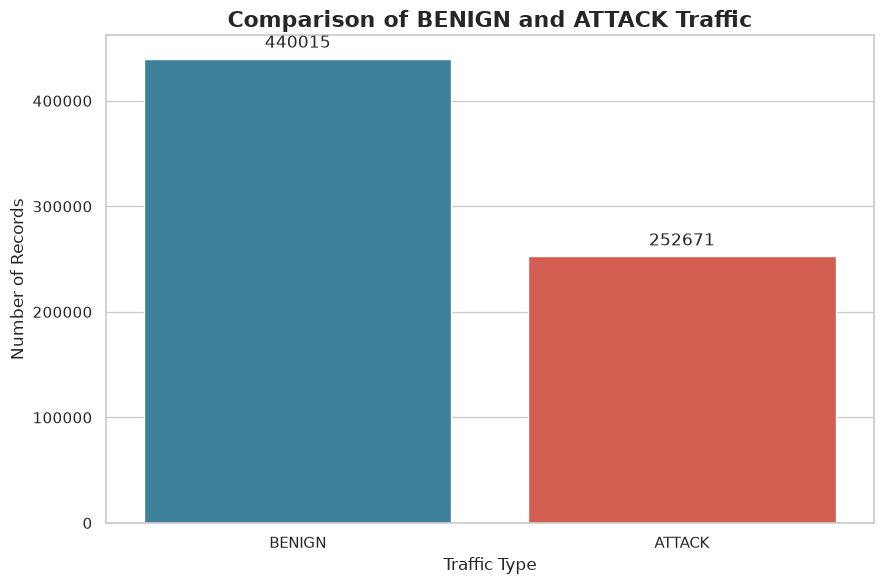

Traffic Type Percentages:
Traffic Type
BENIGN    63.52
ATTACK    36.48
Name: count, dtype: float64


In [4]:
# Count BENIGN and ATTACK records
traffic_counts = df["Traffic Type"].value_counts()

# Create bar chart
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=traffic_counts.index,
    y=traffic_counts.values,
    hue=traffic_counts.index,
    palette=["#2E86AB", "#E74C3C"],
    legend=False
)

# Display record counts
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=5)

# Add chart title and labels
plt.title(
    "Comparison of BENIGN and ATTACK Traffic",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Traffic Type", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

plt.tight_layout()

# Save visualization
plt.savefig(
    "../Visualizations/Static/02_BENIGN_vs_ATTACK_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display percentages
print("Traffic Type Percentages:")
print((traffic_counts / len(df) * 100).round(2))

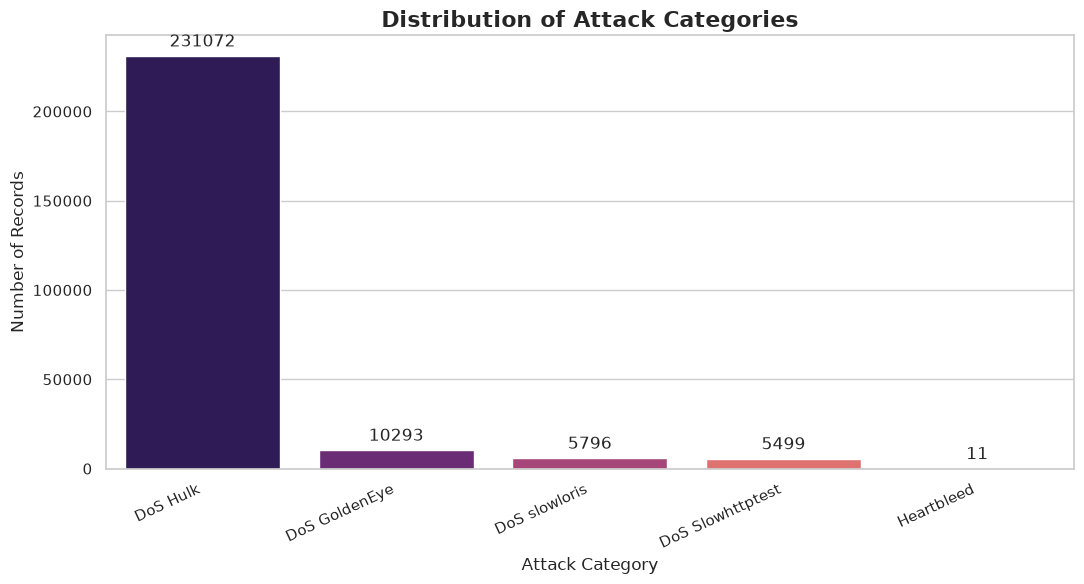

Attack Category Percentages:
Label
DoS Hulk            91.45
DoS GoldenEye        4.07
DoS slowloris        2.29
DoS Slowhttptest     2.18
Heartbleed           0.00
Name: count, dtype: float64


In [ ]:
# Filter out BENIGN traffic
attack_df = df[df["Label"] != "BENIGN"]

# Count records for each attack category
attack_counts = attack_df["Label"].value_counts()

# Create bar chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=attack_counts.index,
    y=attack_counts.values,
    hue=attack_counts.index,
    palette="magma",
    legend=False
)

# Display record counts
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

# Add title and axis labels
plt.title(
    "Distribution of Attack Categories",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Attack Category", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()

# Save visualization
plt.savefig(
    "../Visualizations/Static/03_Attack_Category_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display attack category percentages
print("Attack Category Percentages:")
print((attack_counts / len(attack_df) * 100).round(2))

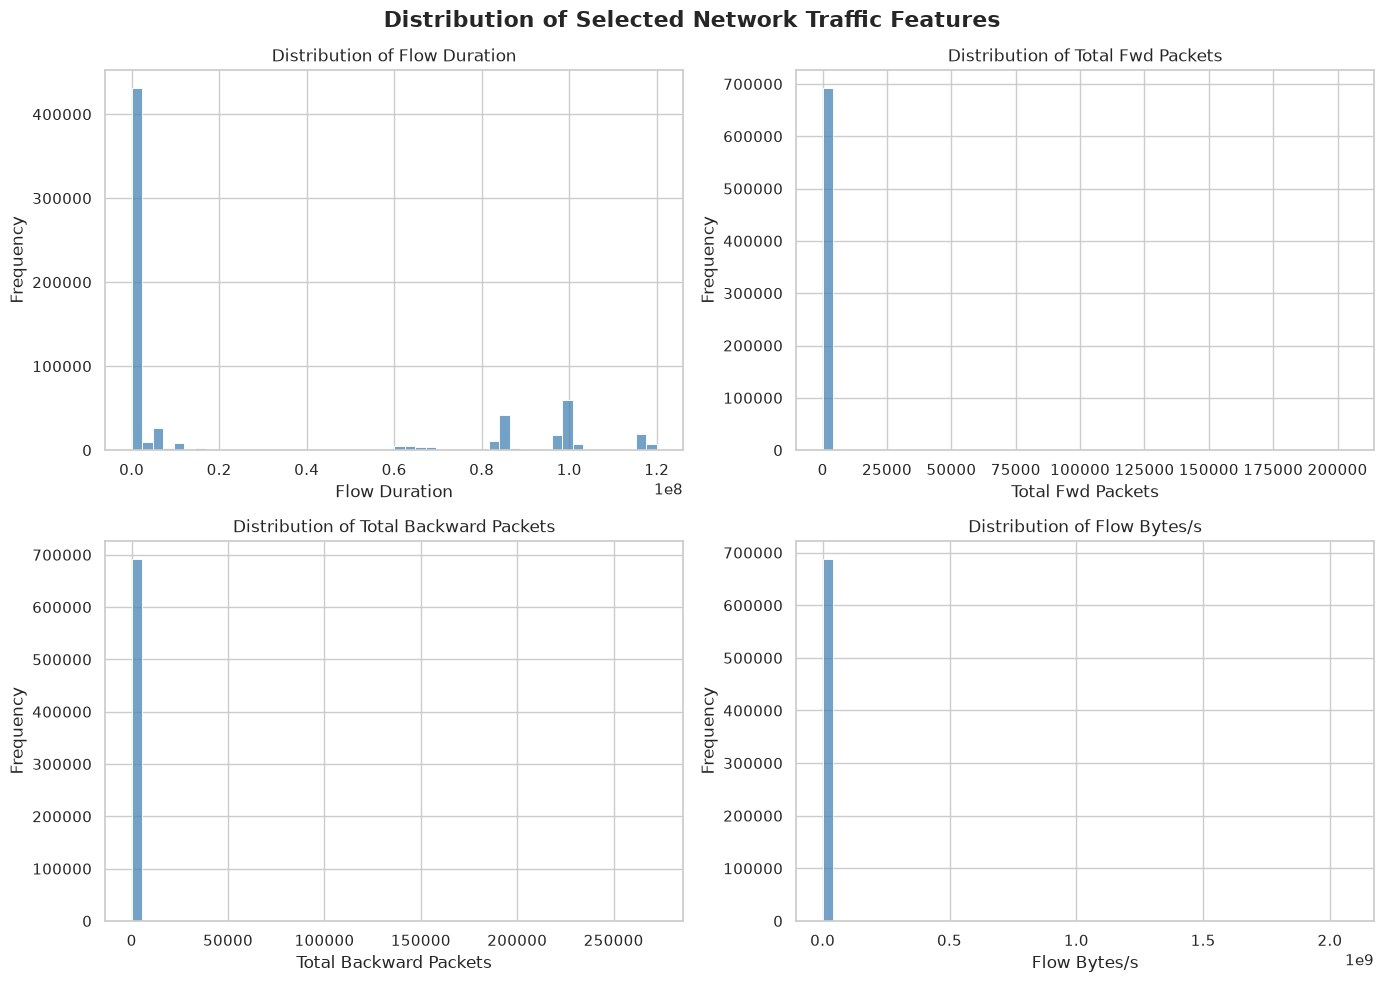

In [6]:
# Select numerical features
features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s"
]

# Create a 2x2 grid of histograms
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes = axes.flatten()

for i, feature in enumerate(features):

    # Remove missing and infinite values for plotting
    values = df[feature].replace([np.inf, -np.inf], np.nan).dropna()

    sns.histplot(
        values,
        bins=50,
        kde=False,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"Distribution of {feature}", fontsize=12)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Frequency")

plt.suptitle(
    "Distribution of Selected Network Traffic Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Save visualization
plt.savefig(
    "../Visualizations/Static/04_Numerical_Feature_Distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

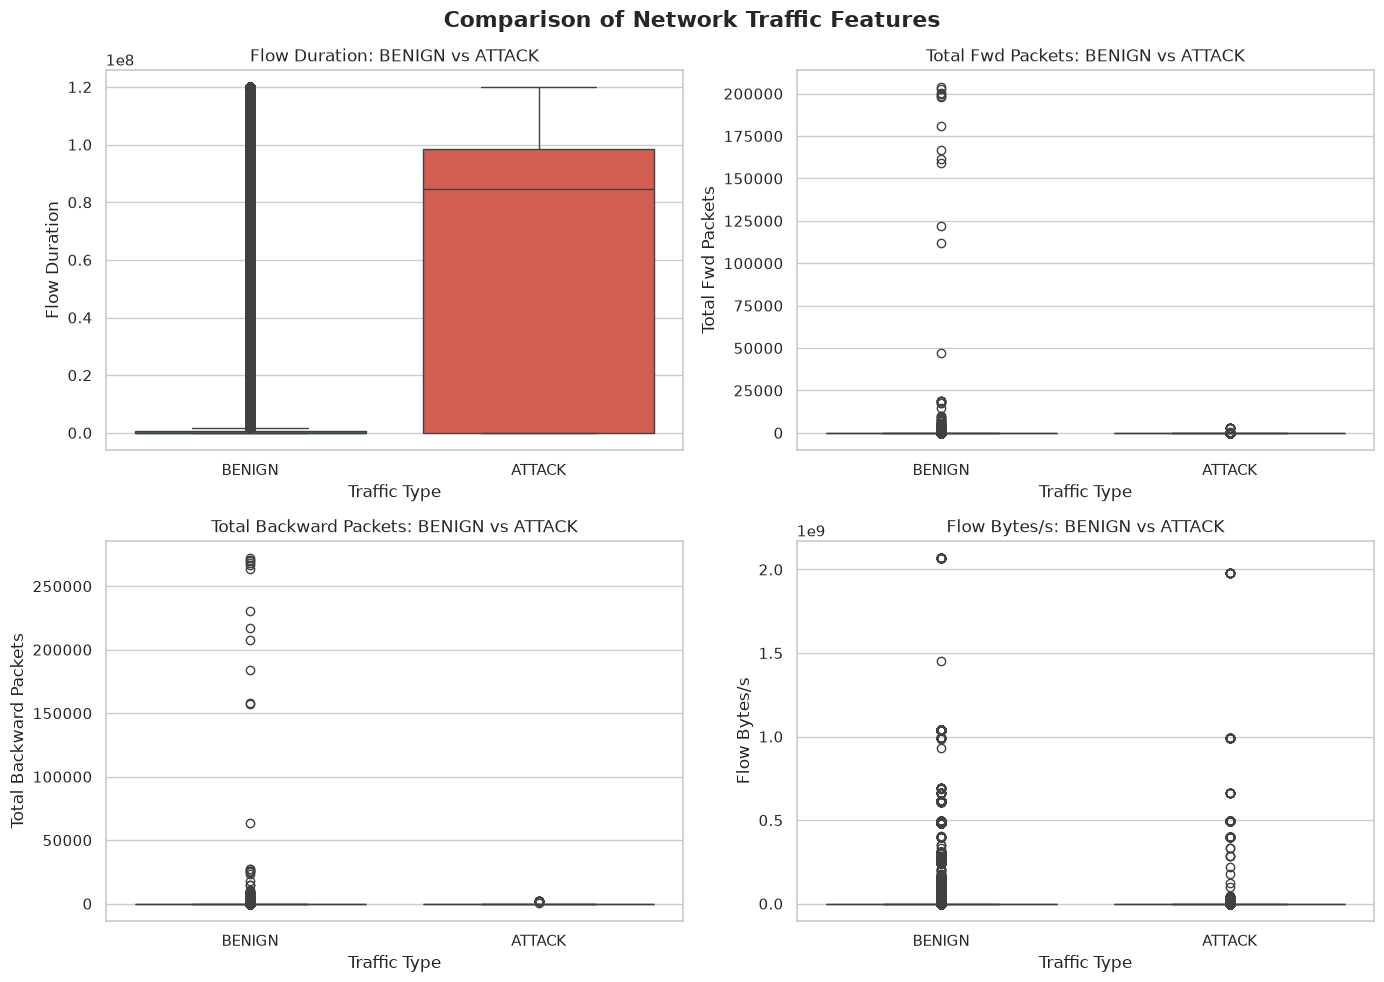

In [7]:
# ==========================================
# PHASE 5: DATA VISUALIZATION
# STEP 6: BENIGN VS ATTACK FEATURE COMPARISON
# ==========================================

# Select features for comparison
features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s"
]

# Create a 2x2 grid of box plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes = axes.flatten()

for i, feature in enumerate(features):

    # Remove missing and infinite values
    plot_df = df[["Traffic Type", feature]].copy()

    plot_df[feature] = plot_df[feature].replace(
        [np.inf, -np.inf], np.nan
    )

    plot_df = plot_df.dropna()

    # Draw box plot
    sns.boxplot(
        data=plot_df,
        x="Traffic Type",
        y=feature,
        hue="Traffic Type",
        palette=["#2E86AB", "#E74C3C"],
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{feature}: BENIGN vs ATTACK",
        fontsize=12
    )

    axes[i].set_xlabel("Traffic Type")
    axes[i].set_ylabel(feature)

plt.suptitle(
    "Comparison of Network Traffic Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Save visualization
plt.savefig(
    "../Visualizations/Static/05_BENIGN_vs_ATTACK_Feature_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

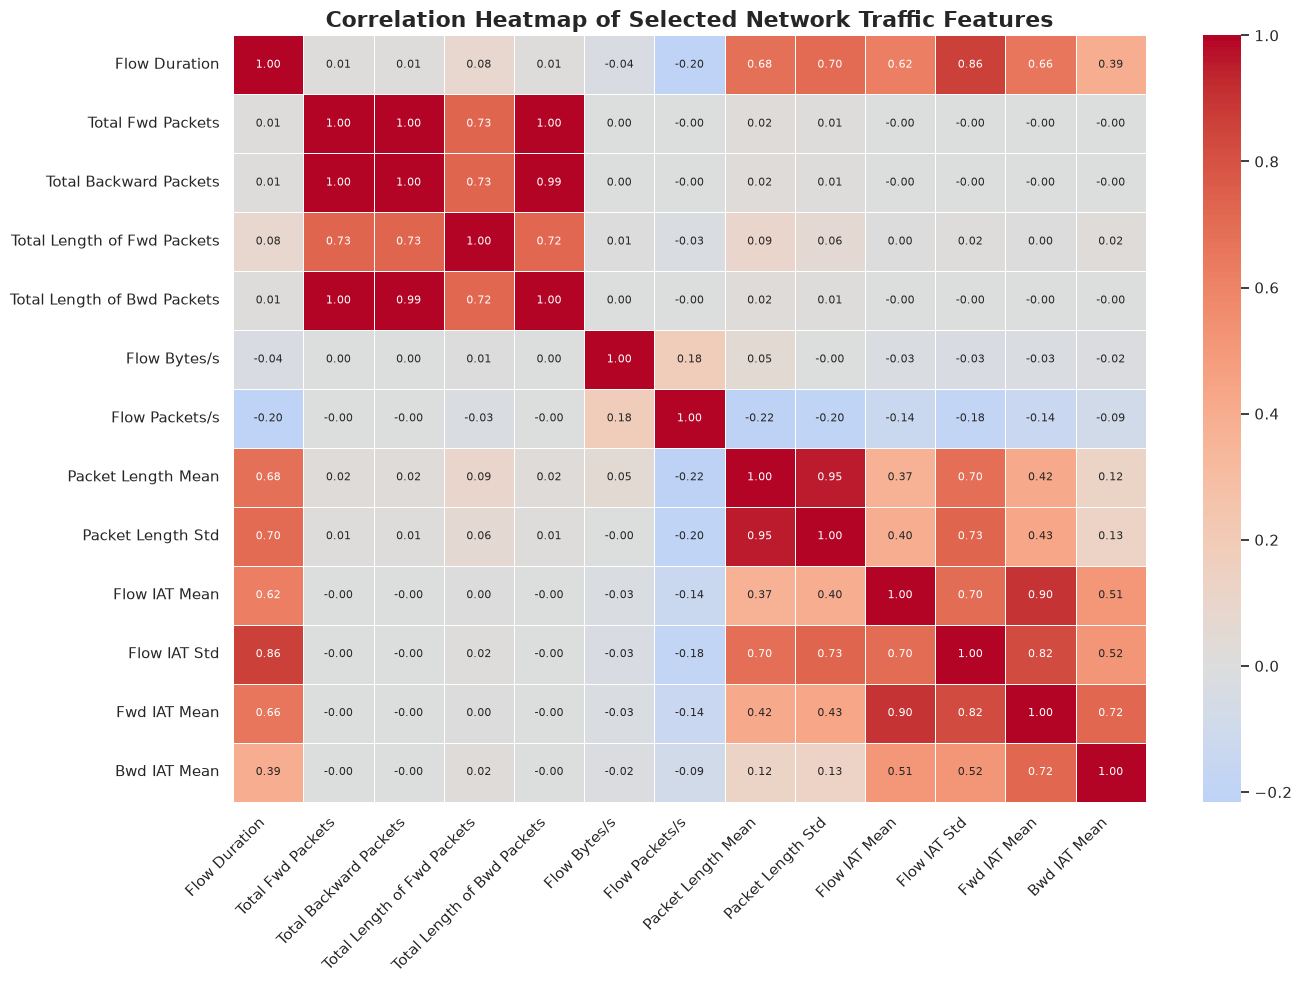

In [8]:
# ==========================================
# PHASE 5: DATA VISUALIZATION
# STEP 7: CORRELATION HEATMAP
# ==========================================

# Select important numerical features
features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean",
    "Packet Length Std",
    "Flow IAT Mean",
    "Flow IAT Std",
    "Fwd IAT Mean",
    "Bwd IAT Mean"
]

# Calculate correlation matrix
correlation_matrix = df[features].corr()

# Create heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    annot_kws={"size": 8}
)

plt.title(
    "Correlation Heatmap of Selected Network Traffic Features",
    fontsize=16,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

# Save visualization
plt.savefig(
    "../Visualizations/Static/06_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

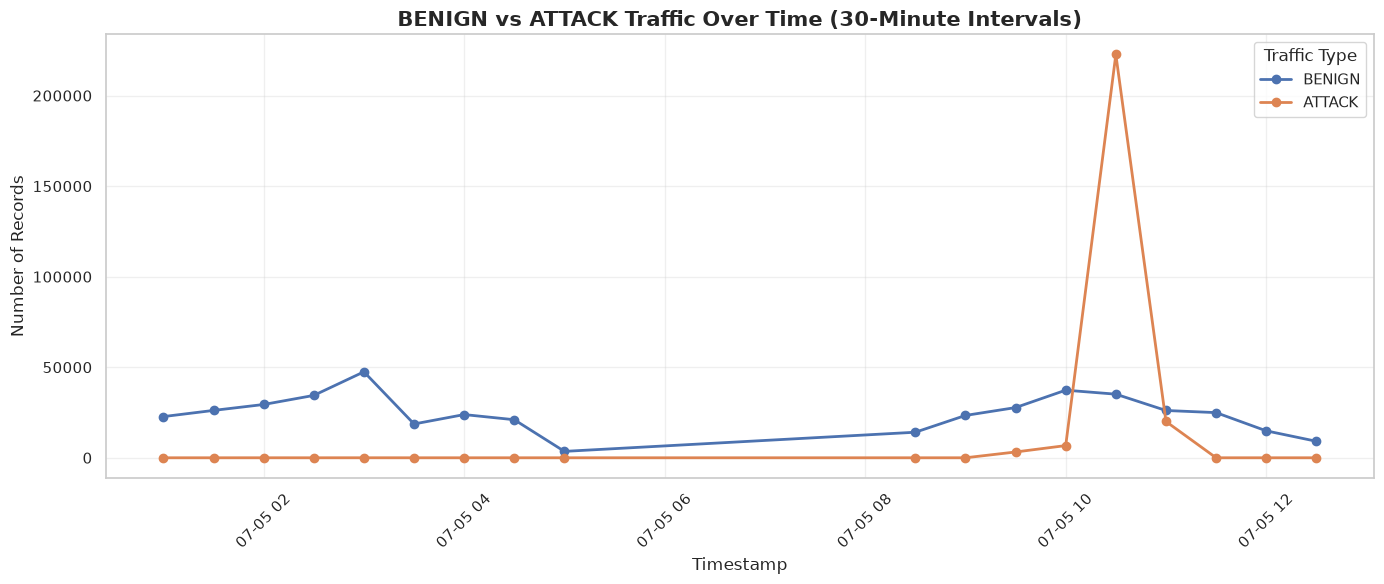

Traffic Counts by 30-Minute Interval:


Traffic Type,ATTACK,BENIGN
Timestamp,,
2017-07-05 01:00:00,0,22746
2017-07-05 01:30:00,0,26156
2017-07-05 02:00:00,5,29426
2017-07-05 02:30:00,0,34437
2017-07-05 03:00:00,9,47467
2017-07-05 03:30:00,2,18662
2017-07-05 04:00:00,0,23862
2017-07-05 04:30:00,0,21015
2017-07-05 05:00:00,0,3535


In [9]:
# ==========================================
# PHASE 5: DATA VISUALIZATION
# STEP 8: TIME-BASED TRAFFIC VISUALIZATION
# ==========================================

# Create a temporary time-based dataset
time_df = df[["Timestamp", "Traffic Type"]].copy()

# Remove records with missing timestamps
time_df = time_df.dropna(subset=["Timestamp"])

# Group traffic records into 30-minute intervals
time_traffic = (
    time_df
    .set_index("Timestamp")
    .groupby([
        pd.Grouper(freq="30min"),
        "Traffic Type"
    ])
    .size()
    .unstack(fill_value=0)
)

# Create line chart
plt.figure(figsize=(14, 6))

for traffic_type in ["BENIGN", "ATTACK"]:
    if traffic_type in time_traffic.columns:
        plt.plot(
            time_traffic.index,
            time_traffic[traffic_type],
            marker="o",
            linewidth=2,
            label=traffic_type
        )

# Add chart title and labels
plt.title(
    "BENIGN vs ATTACK Traffic Over Time (30-Minute Intervals)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Timestamp", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

plt.xticks(rotation=45)
plt.legend(title="Traffic Type")
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save visualization
plt.savefig(
    "../Visualizations/Static/07_Time_Based_Traffic_Visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display the grouped data
print("Traffic Counts by 30-Minute Interval:")
display(time_traffic)

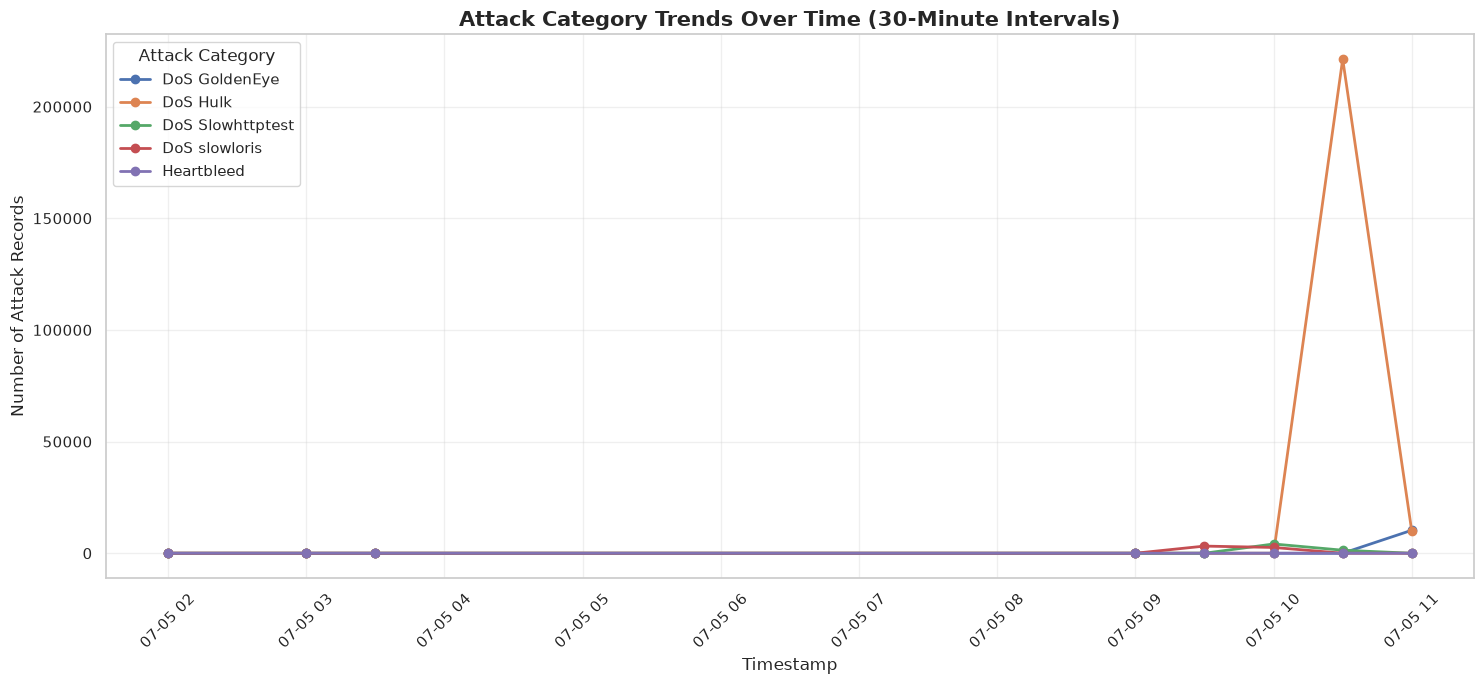

Attack Records by 30-Minute Interval:


Label,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,Heartbleed
Timestamp,,,,,
2017-07-05 02:00:00,0,0,0,5,0
2017-07-05 03:00:00,0,0,0,0,9
2017-07-05 03:30:00,0,0,0,0,2
2017-07-05 09:00:00,0,0,0,1,0
2017-07-05 09:30:00,0,0,0,3200,0
2017-07-05 10:00:00,0,0,4144,2590,0
2017-07-05 10:30:00,0,221330,1355,0,0
2017-07-05 11:00:00,10293,9742,0,0,0


In [10]:
# ==========================================
# PHASE 5: DATA VISUALIZATION
# STEP 9: ATTACK CATEGORY TRENDS OVER TIME
# ==========================================

# Select attack records only
attack_time_df = df[df["Label"] != "BENIGN"][
    ["Timestamp", "Label"]
].copy()

# Remove records with missing timestamps
attack_time_df = attack_time_df.dropna(subset=["Timestamp"])

# Group attack records into 30-minute intervals
attack_trends = (
    attack_time_df
    .set_index("Timestamp")
    .groupby([
        pd.Grouper(freq="30min"),
        "Label"
    ])
    .size()
    .unstack(fill_value=0)
)

# Create line chart
plt.figure(figsize=(15, 7))

for attack_category in attack_trends.columns:
    plt.plot(
        attack_trends.index,
        attack_trends[attack_category],
        marker="o",
        linewidth=2,
        label=attack_category
    )

# Add title and axis labels
plt.title(
    "Attack Category Trends Over Time (30-Minute Intervals)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Timestamp", fontsize=12)
plt.ylabel("Number of Attack Records", fontsize=12)

plt.xticks(rotation=45)
plt.legend(title="Attack Category")
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save visualization
plt.savefig(
    "../Visualizations/Static/08_Attack_Category_Trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display grouped attack counts
print("Attack Records by 30-Minute Interval:")
display(attack_trends)

In [11]:
# ==========================================
# PHASE 5: DATA VISUALIZATION
# STEP 10A: INTERACTIVE TRAFFIC DISTRIBUTION
# ==========================================

# Count records for each traffic category
label_counts = df["Label"].value_counts().reset_index()

label_counts.columns = ["Traffic Category", "Record Count"]

# Create interactive bar chart
fig = px.bar(
    label_counts,
    x="Traffic Category",
    y="Record Count",
    color="Traffic Category",
    text="Record Count",
    title="Interactive Distribution of Network Traffic Categories",
    template="plotly_white"
)

fig.update_traces(
    textposition="outside"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Traffic Category",
    yaxis_title="Number of Records",
    showlegend=False
)

# Save interactive chart
fig.write_html(
    "../Visualizations/Interactive/01_Interactive_Traffic_Distribution.html"
)

fig.show()

In [12]:
# ==========================================
# PHASE 5: DATA VISUALIZATION
# STEP 10B: INTERACTIVE TIME-BASED TRAFFIC
# ==========================================

# Prepare timestamp data
time_df = df[["Timestamp", "Traffic Type"]].dropna(
    subset=["Timestamp"]
).copy()

# Group records into 30-minute intervals
time_traffic = (
    time_df
    .set_index("Timestamp")
    .groupby([
        pd.Grouper(freq="30min"),
        "Traffic Type"
    ])
    .size()
    .reset_index(name="Record Count")
)

# Create interactive line chart
fig = px.line(
    time_traffic,
    x="Timestamp",
    y="Record Count",
    color="Traffic Type",
    markers=True,
    title="Interactive BENIGN vs ATTACK Traffic Over Time",
    template="plotly_white"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Timestamp",
    yaxis_title="Number of Records",
    hovermode="x unified"
)

# Save interactive chart
fig.write_html(
    "../Visualizations/Interactive/02_Interactive_Time_Based_Traffic.html"
)

fig.show()